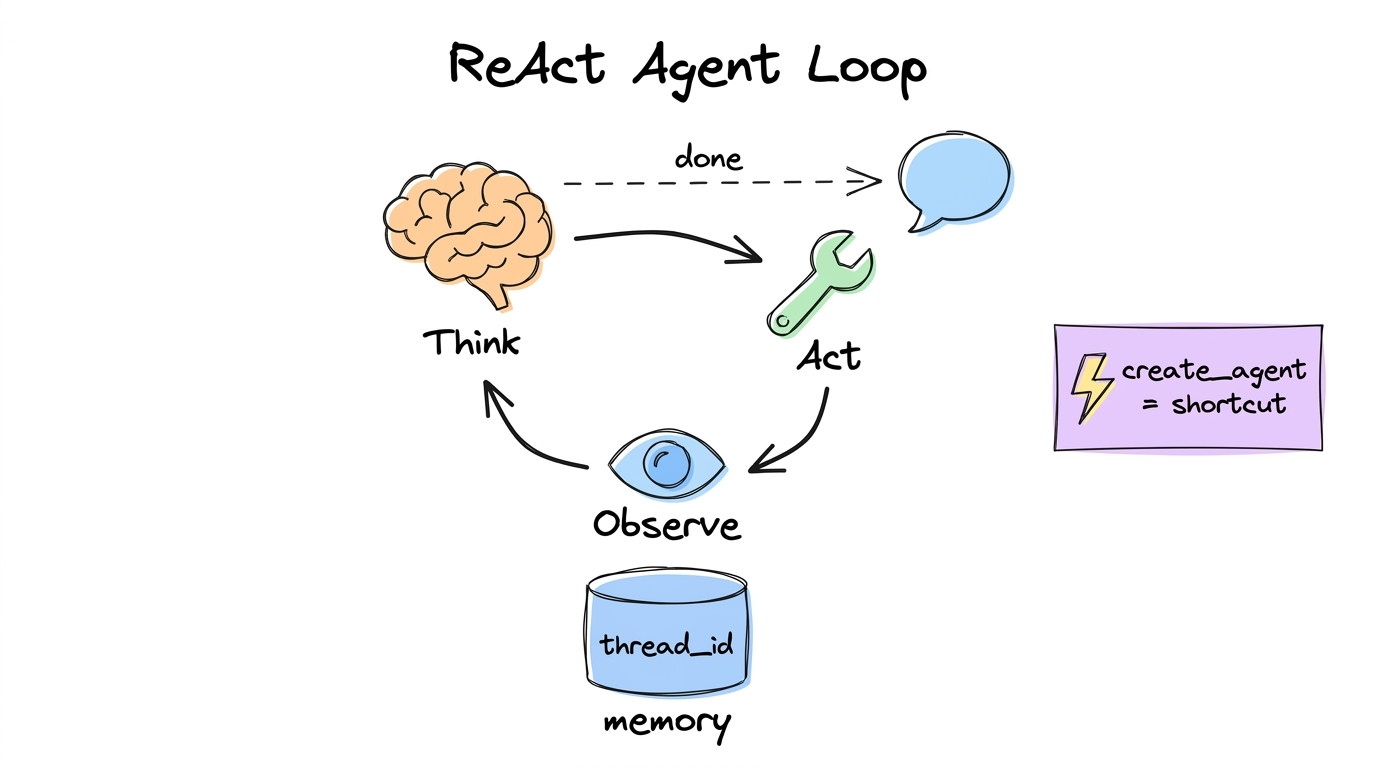

#### ReAct Agent Architecture
##### Aim
This is the intuition behind ReAct, a general agent architecture.

1. act - let the model call specific tools
2. observe - pass the tool output back to the model
3. reason - let the model reason about the tool output to decide what to do next (e.g., call another tool or just respond directly)

In [1]:
from dotenv import load_dotenv
load_dotenv() 

True

In [2]:
import re
import arxiv
from langchain_core.tools import tool

# page_size / retries keep us polite with arXiv's rate limits
arxiv_client = arxiv.Client(page_size=2, delay_seconds=5, num_retries=5)

@tool
def arxiv_search(query: str) -> str:
    """Search arXiv for research papers. Accepts keywords, a title, or an arXiv id such as 1706.03762."""
    if re.fullmatch(r"\d{4}\.\d{4,5}", query.strip()):
        search = arxiv.Search(id_list=[query.strip()])
    else:
        search = arxiv.Search(query=query, max_results=2)
    papers = arxiv_client.results(search)
    return "\n\n".join(f"Title: {p.title}\nPublished: {p.published.date()}\nSummary: {p.summary[:500]}" for p in papers)

print(arxiv_search.name)

arxiv_search


In [3]:
arxiv_search.invoke("1706.03762")

'Title: Attention Is All You Need\nPublished: 2017-06-12\nSummary: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more '

In [4]:
import wikipedia

wikipedia.set_user_agent("langgraph-teaching-notebooks/1.0 (educational)")

@tool
def wikipedia_search(query: str) -> str:
    """Look up a topic on Wikipedia and return a short summary."""
    titles = wikipedia.search(query, results=1)
    if not titles:
        return "No Wikipedia page found."
    try:
        return wikipedia.summary(titles[0], sentences=4, auto_suggest=False)
    except wikipedia.DisambiguationError as e:
        return wikipedia.summary(e.options[0], sentences=4, auto_suggest=False)

wikipedia_search.name

'wikipedia_search'

In [5]:
wikipedia_search.invoke("What is machine learning")

'Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.\nStatistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.\nFrom a theoretical viewpoint, probably approximately correct learning provides a mathematical and statistical framework for describing machine learning.'